
Crop Recommendation Classification using XGBoost
==================================================
Complete end-to-end pipeline: EDA, preprocessing, training, evaluation,
and rich visualizations.
 
Author: Aakash Kavediya

 

#### Importing Dependencies

In [1]:
import warnings
warnings.filterwarnings("ignore")
 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.gridspec import GridSpec
 
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    precision_score, recall_score, f1_score, roc_curve, auc,
    ConfusionMatrixDisplay
)
from sklearn.preprocessing import label_binarize
 
import xgboost as xgb
from xgboost import XGBClassifier
 
import joblib
import os

#### CONFIG

In [2]:
DATA_PATH = "../Dataset/Crop_recommendation.csv"
OUT_DIR = "outputs"  # relative folder created next to this notebook
os.makedirs(OUT_DIR, exist_ok=True)
print("Saving all outputs to:", os.path.abspath(OUT_DIR))
 
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

Saving all outputs to: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\Crop_recommendation\outputs


#### LOAD DATA

In [3]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
print(df.head())
print("\nClass distribution:\n", df["label"].value_counts())
 
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"

Dataset shape: (2200, 8)
    N   P   K  temperature   humidity        ph    rainfall label
0  90  42  43    20.879744  82.002744  6.502985  202.935536  rice
1  85  58  41    21.770462  80.319644  7.038096  226.655537  rice
2  60  55  44    23.004459  82.320763  7.840207  263.964248  rice
3  74  35  40    26.491096  80.158363  6.980401  242.864034  rice
4  78  42  42    20.130175  81.604873  7.628473  262.717340  rice

Class distribution:
 label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


#### EXPLORATORY DATA ANALYSIS (EDA) VISUALS

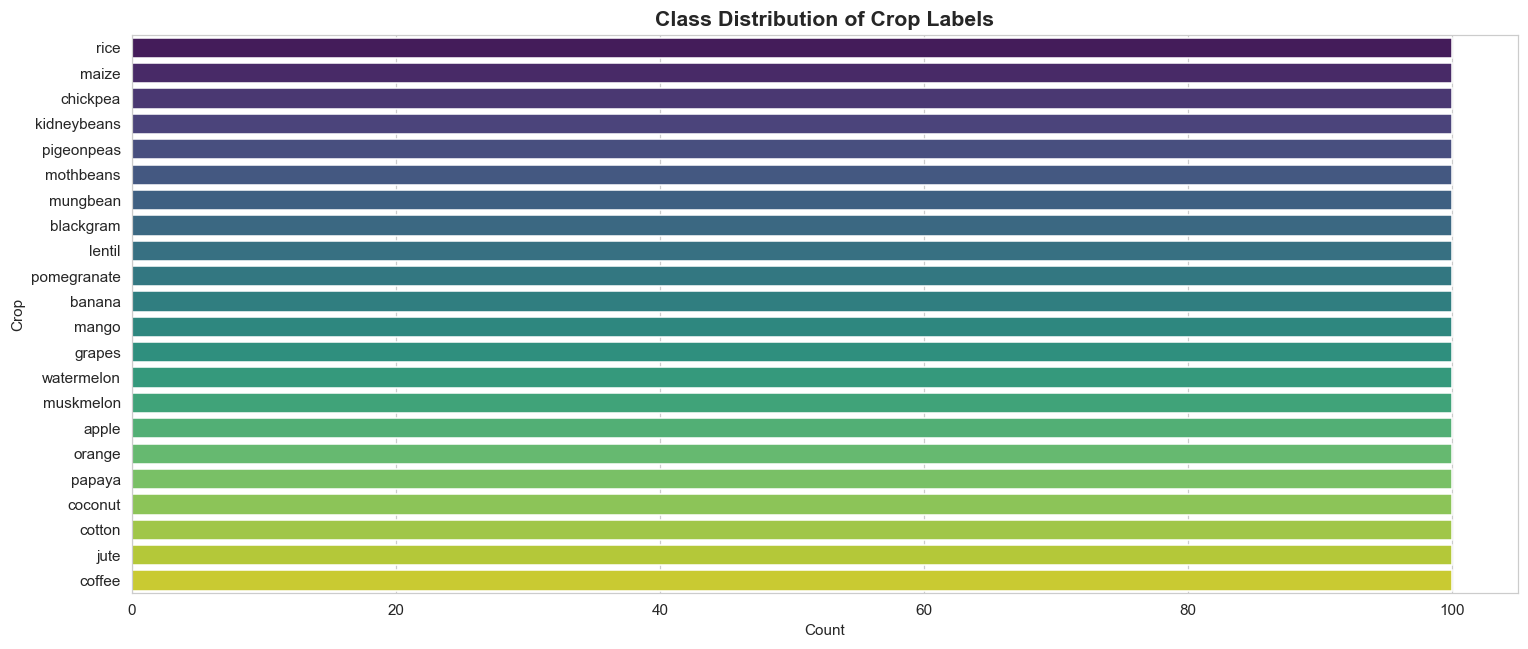

In [4]:
# 2a. Class distribution
plt.figure(figsize=(14, 6))
order = df[TARGET].value_counts().index
sns.countplot(data=df, y=TARGET, order=order, palette="viridis")
plt.title("Class Distribution of Crop Labels", fontsize=14, fontweight="bold")
plt.xlabel("Count")
plt.ylabel("Crop")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/01_class_distribution.png")
plt.show()
plt.close()

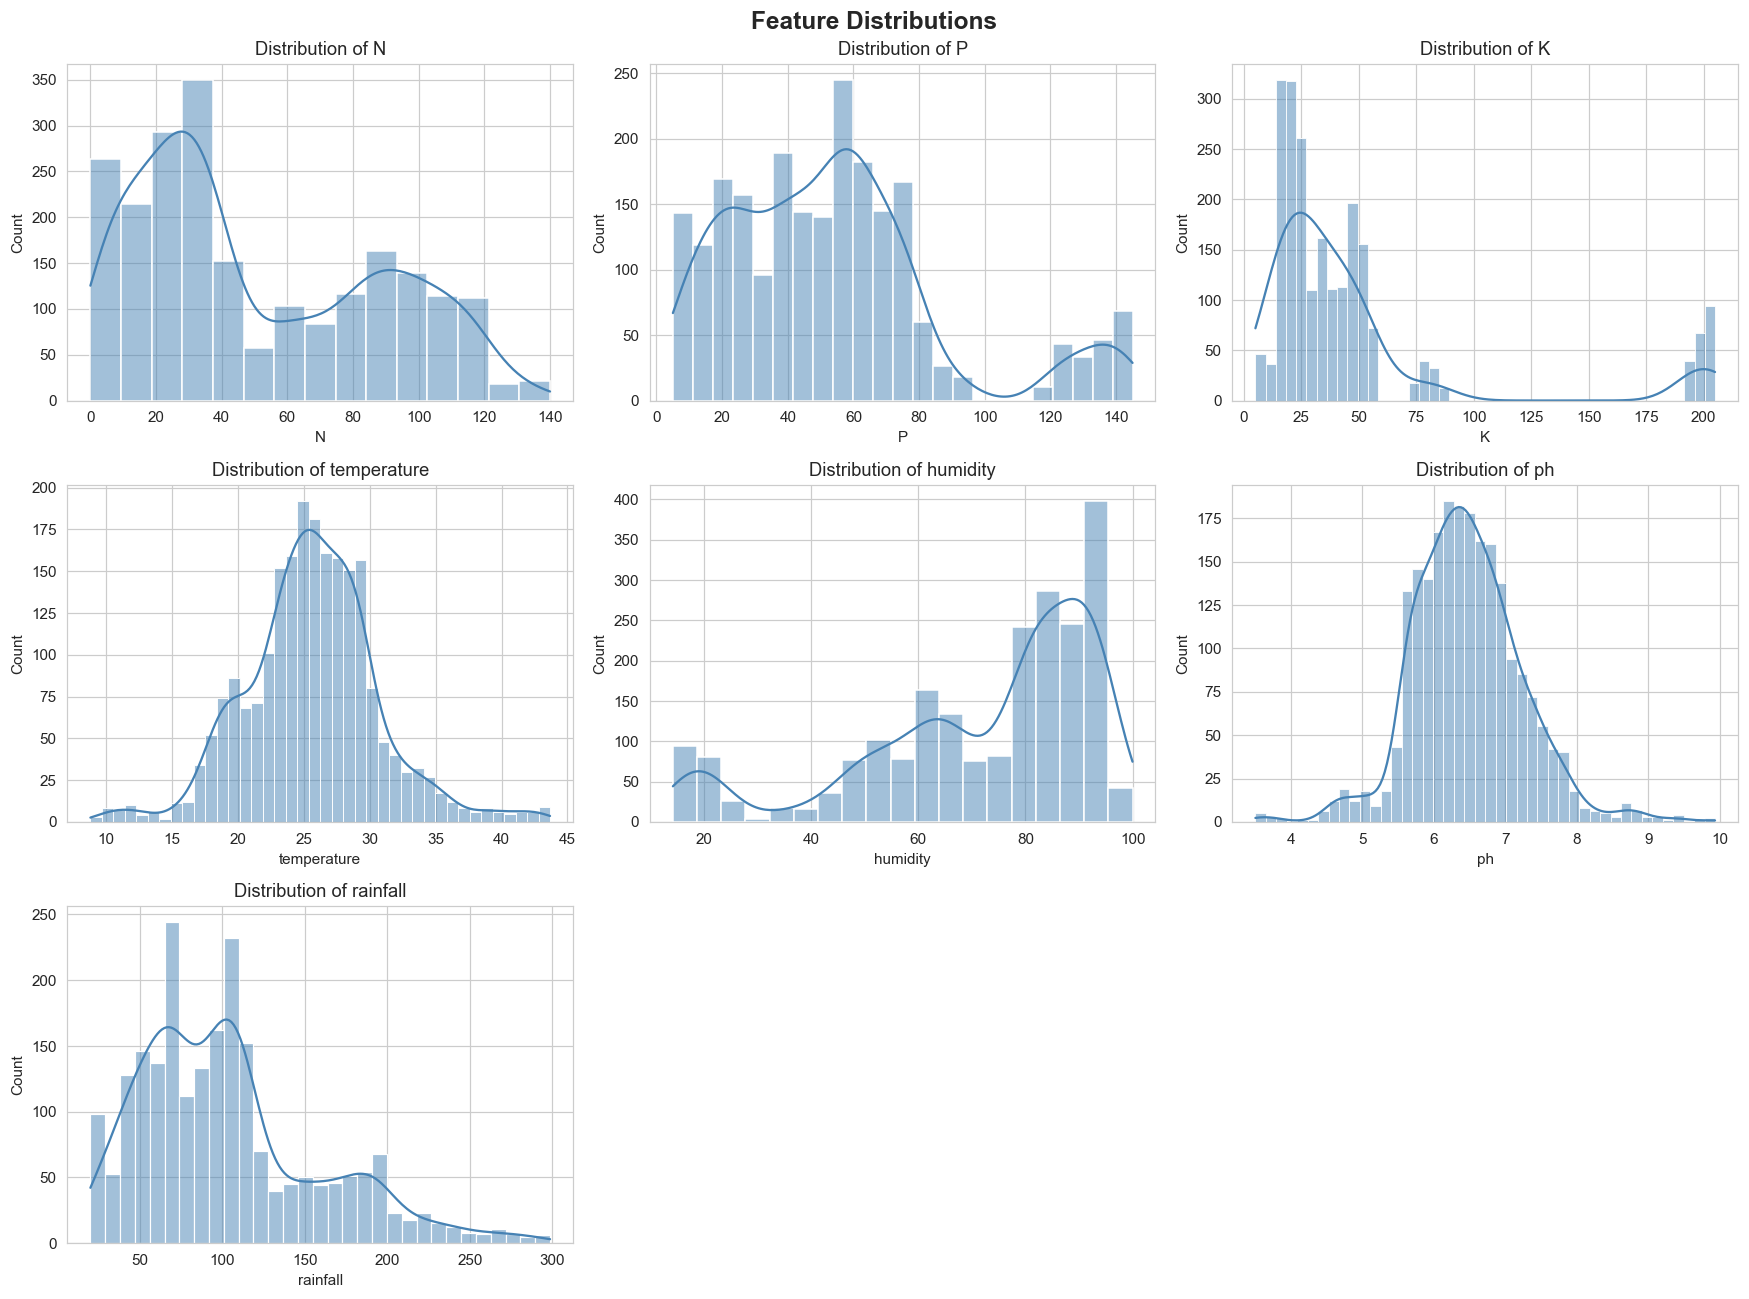

In [5]:
# 2b. Feature distributions (histograms)
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(FEATURES):
    sns.histplot(df[col], kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col}")
for j in range(len(FEATURES), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Feature Distributions", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/02_feature_distributions.png")
plt.show()
plt.close()

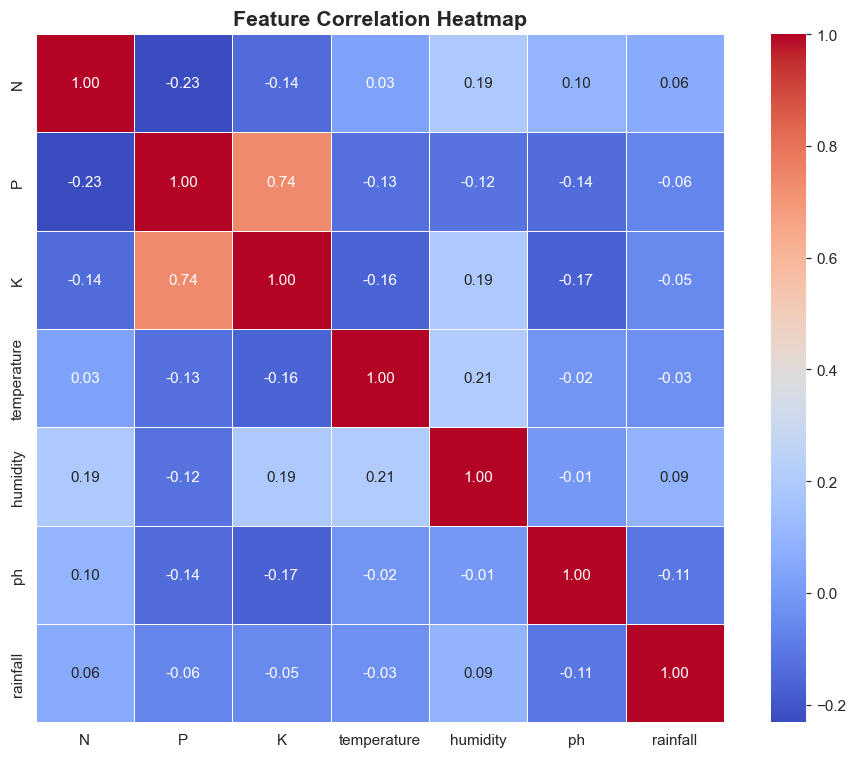

In [6]:
# 2c. Correlation heatmap
plt.figure(figsize=(9, 7))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", square=True, linewidths=0.5)
plt.title("Feature Correlation Heatmap", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/03_correlation_heatmap.png")
plt.show()
plt.close()

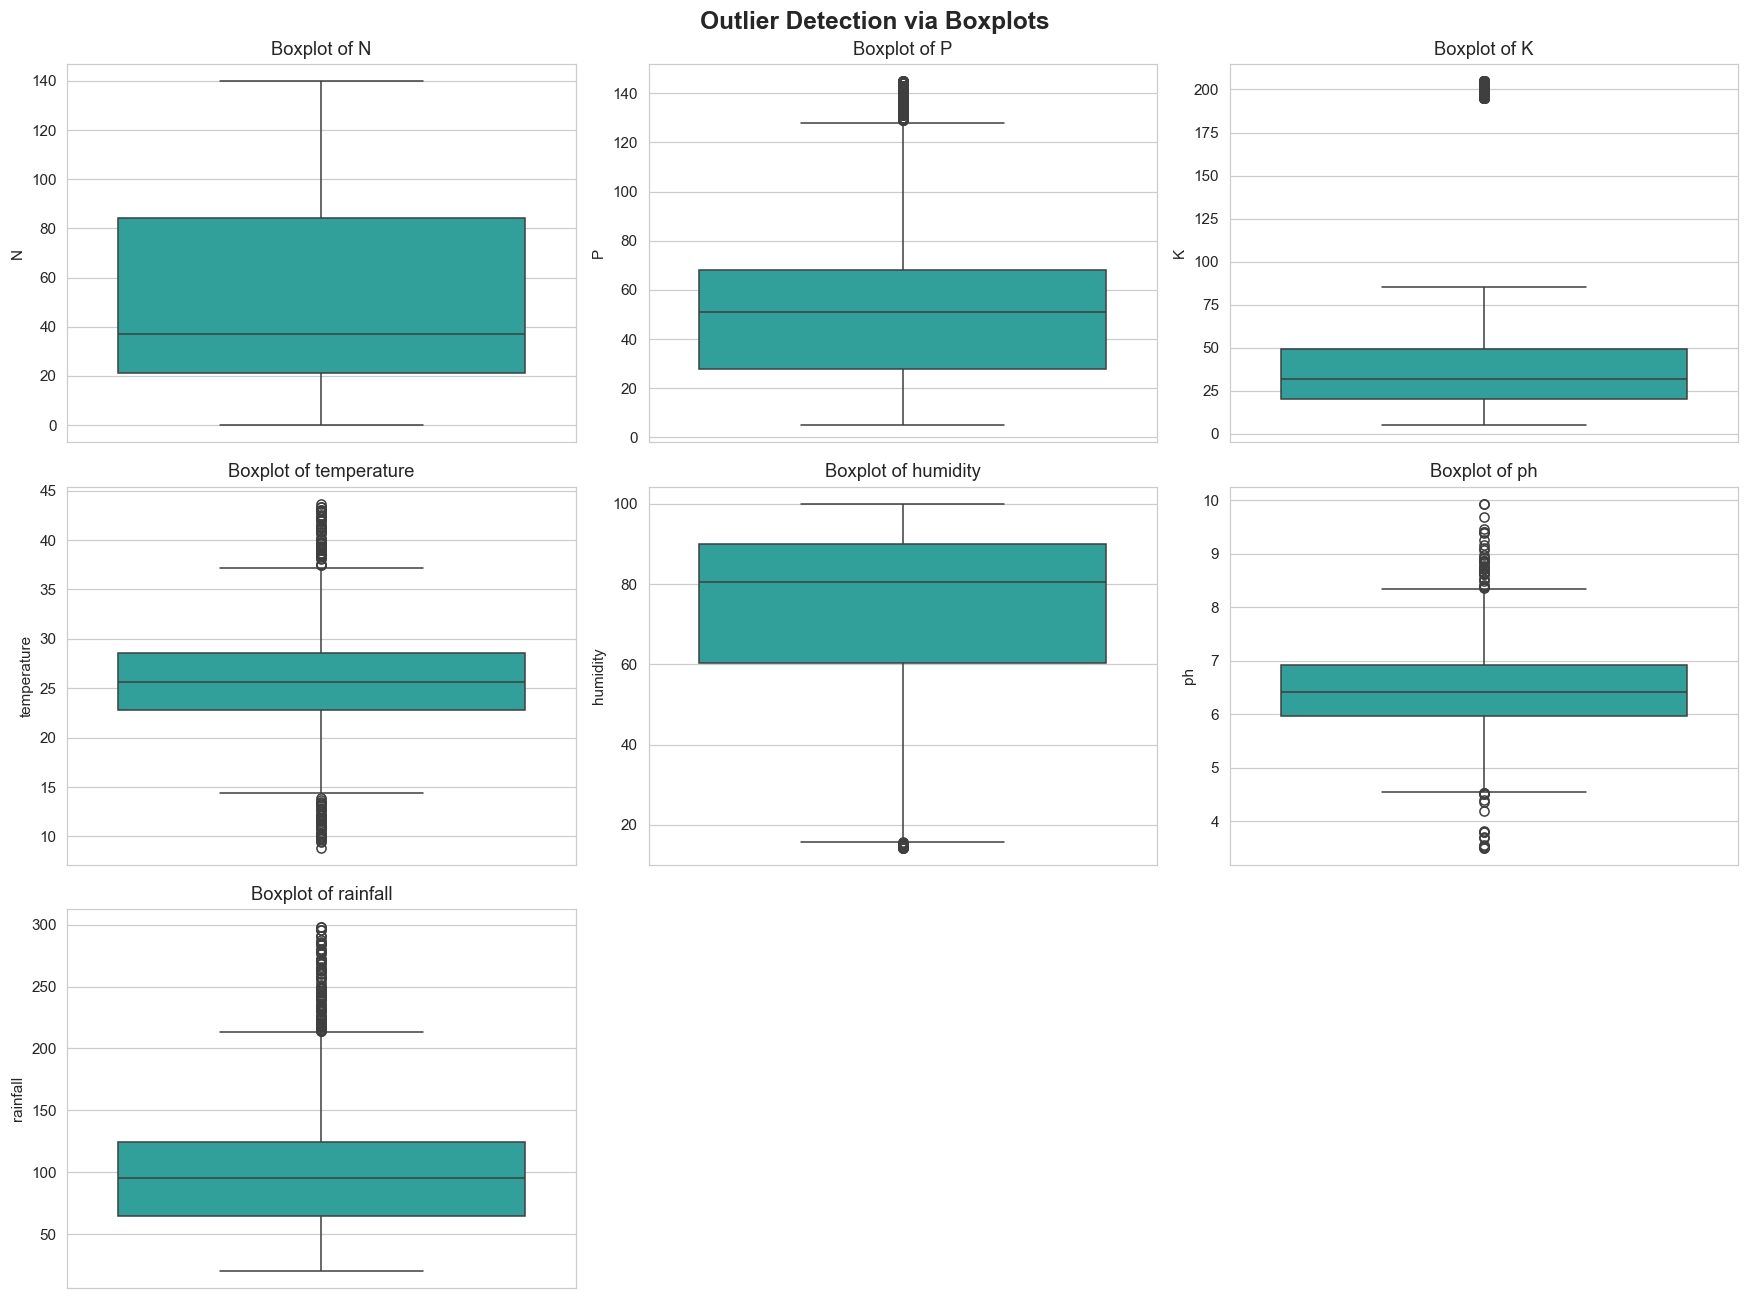

In [7]:
# 2d. Boxplots per feature to spot outliers
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()
for i, col in enumerate(FEATURES):
    sns.boxplot(y=df[col], ax=axes[i], color="lightseagreen")
    axes[i].set_title(f"Boxplot of {col}")
for j in range(len(FEATURES), len(axes)):
    fig.delaxes(axes[j])
plt.suptitle("Outlier Detection via Boxplots", fontsize=16, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/04_boxplots.png")
plt.show()
plt.close()

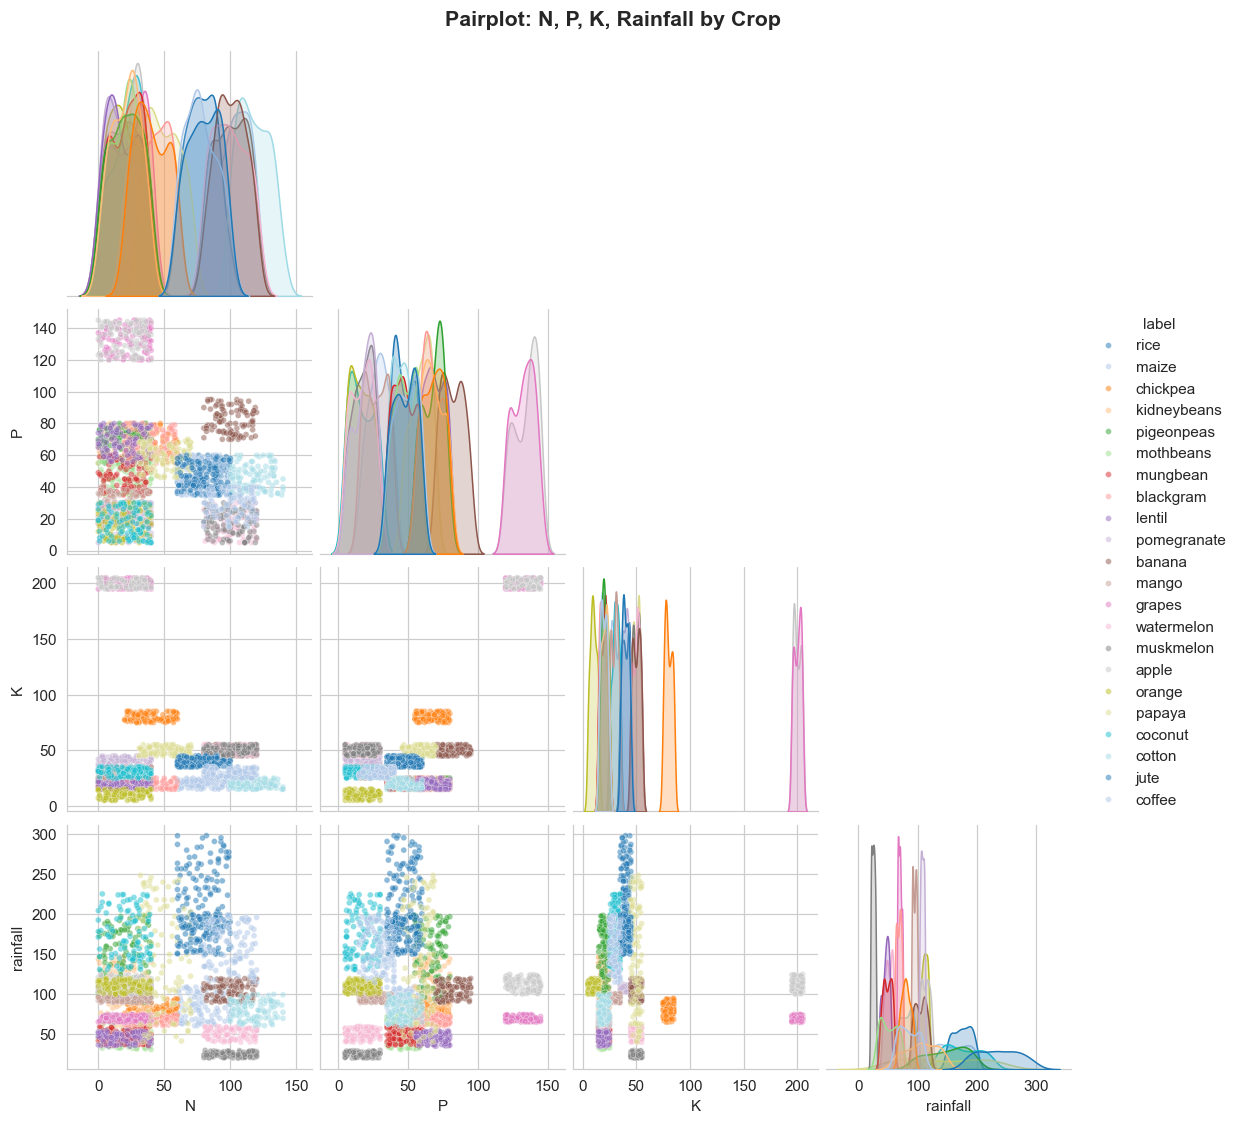

In [8]:
# 2e. Pairplot on a subset of features (colored by label) - sampled for speed
sample_df = df.copy()
g = sns.pairplot(sample_df, vars=["N", "P", "K", "rainfall"], hue=TARGET,
                  palette="tab20", plot_kws={"alpha": 0.5, "s": 15}, corner=True)
g.fig.suptitle("Pairplot: N, P, K, Rainfall by Crop", y=1.02, fontsize=14, fontweight="bold")
g.savefig(f"{OUT_DIR}/05_pairplot.png")
plt.show()
plt.close()

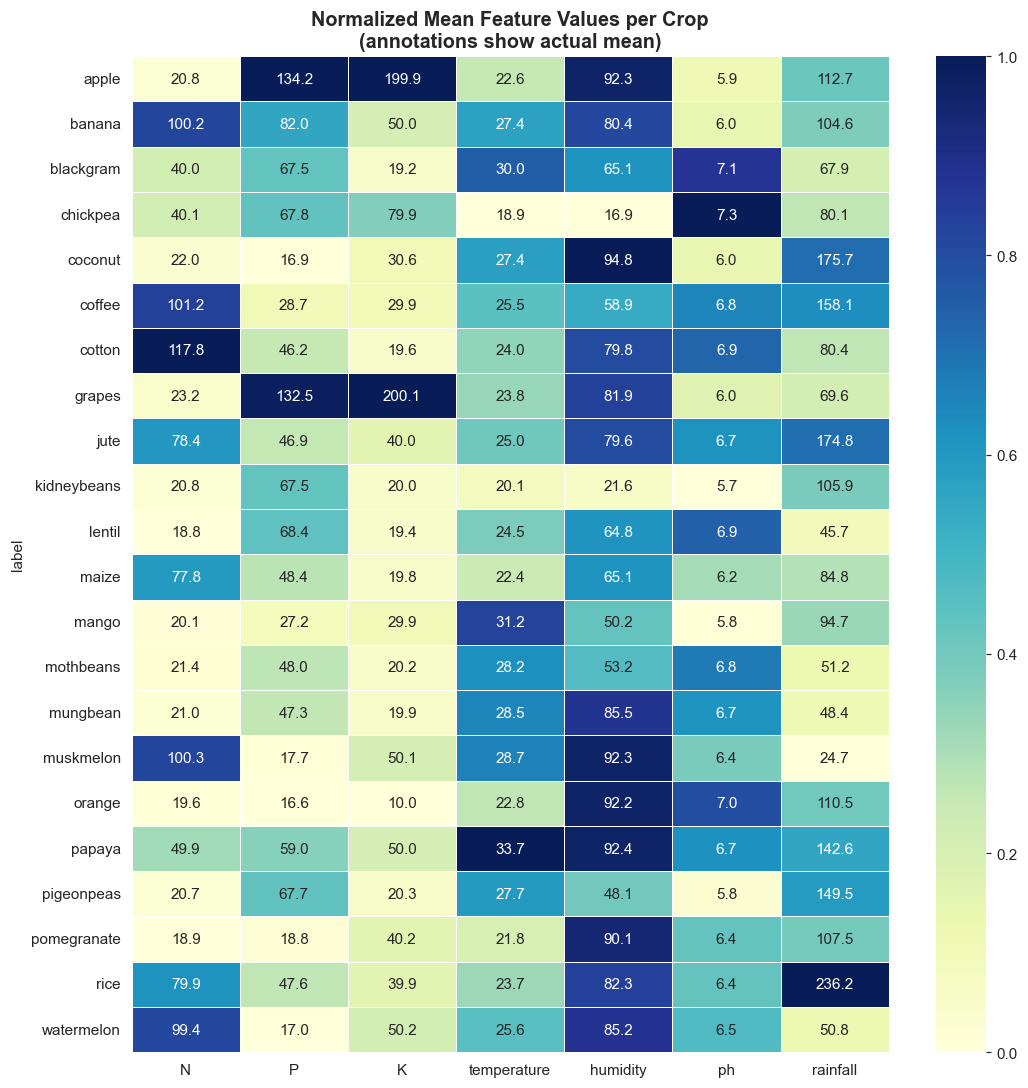


EDA visuals saved.


In [9]:
# 2f. Mean feature values per crop (heatmap)
plt.figure(figsize=(10, 10))
mean_per_crop = df.groupby(TARGET)[FEATURES].mean()
mean_per_crop_scaled = (mean_per_crop - mean_per_crop.min()) / (mean_per_crop.max() - mean_per_crop.min())
sns.heatmap(mean_per_crop_scaled, annot=mean_per_crop.round(1), fmt="", cmap="YlGnBu", linewidths=0.5)
plt.title("Normalized Mean Feature Values per Crop\n(annotations show actual mean)", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/06_mean_feature_per_crop.png")
plt.show()
plt.close()
 
print("\nEDA visuals saved.")

#### PREPROCESSING

In [10]:
le = LabelEncoder()
df["label_encoded"] = le.fit_transform(df[TARGET])
 
X = df[FEATURES]
y = df["label_encoded"]
 
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
 
print(f"\nTrain shape: {X_train.shape}, Test shape: {X_test.shape}")


Train shape: (1760, 7), Test shape: (440, 7)


#### MODEL TRAINING - XGBoost Classifier

In [11]:
xgb_clf = XGBClassifier(
    objective="multi:softprob",
    num_class=len(le.classes_),
    eval_metric="mlogloss",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    tree_method="hist",
)
 
eval_set = [(X_train, y_train), (X_test, y_test)]
xgb_clf.fit(X_train, y_train, eval_set=eval_set, verbose=False)

,objective,'multi:softprob'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,0.8
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,'mlogloss'


#### CROSS VALIDATION

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_scores = cross_val_score(xgb_clf, X, y, cv=skf, scoring="accuracy", n_jobs=-1)
print(f"\n5-Fold CV Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


5-Fold CV Accuracy: 0.9955 (+/- 0.0025)


#### EVALUATION

In [13]:
y_pred = xgb_clf.predict(X_test)
y_proba = xgb_clf.predict_proba(X_test)
 
acc = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred, average="weighted")
rec = recall_score(y_test, y_pred, average="weighted")
f1 = f1_score(y_test, y_pred, average="weighted")
 
print(f"\nTest Accuracy : {acc:.4f}")
print(f"Precision(wt) : {prec:.4f}")
print(f"Recall(wt)    : {rec:.4f}")
print(f"F1-score(wt)  : {f1:.4f}")
 
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, target_names=le.classes_))


Test Accuracy : 0.9909
Precision(wt) : 0.9915
Recall(wt)    : 0.9909
F1-score(wt)  : 0.9909

Classification Report:

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      1.00      1.00        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      0.90      0.95        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.91      1.00      0.95        20
    mungbean       0.95      1.00      0.98        20
   muskmelon     

#### VISUALIZATIONS - MODEL PERFORMANCE

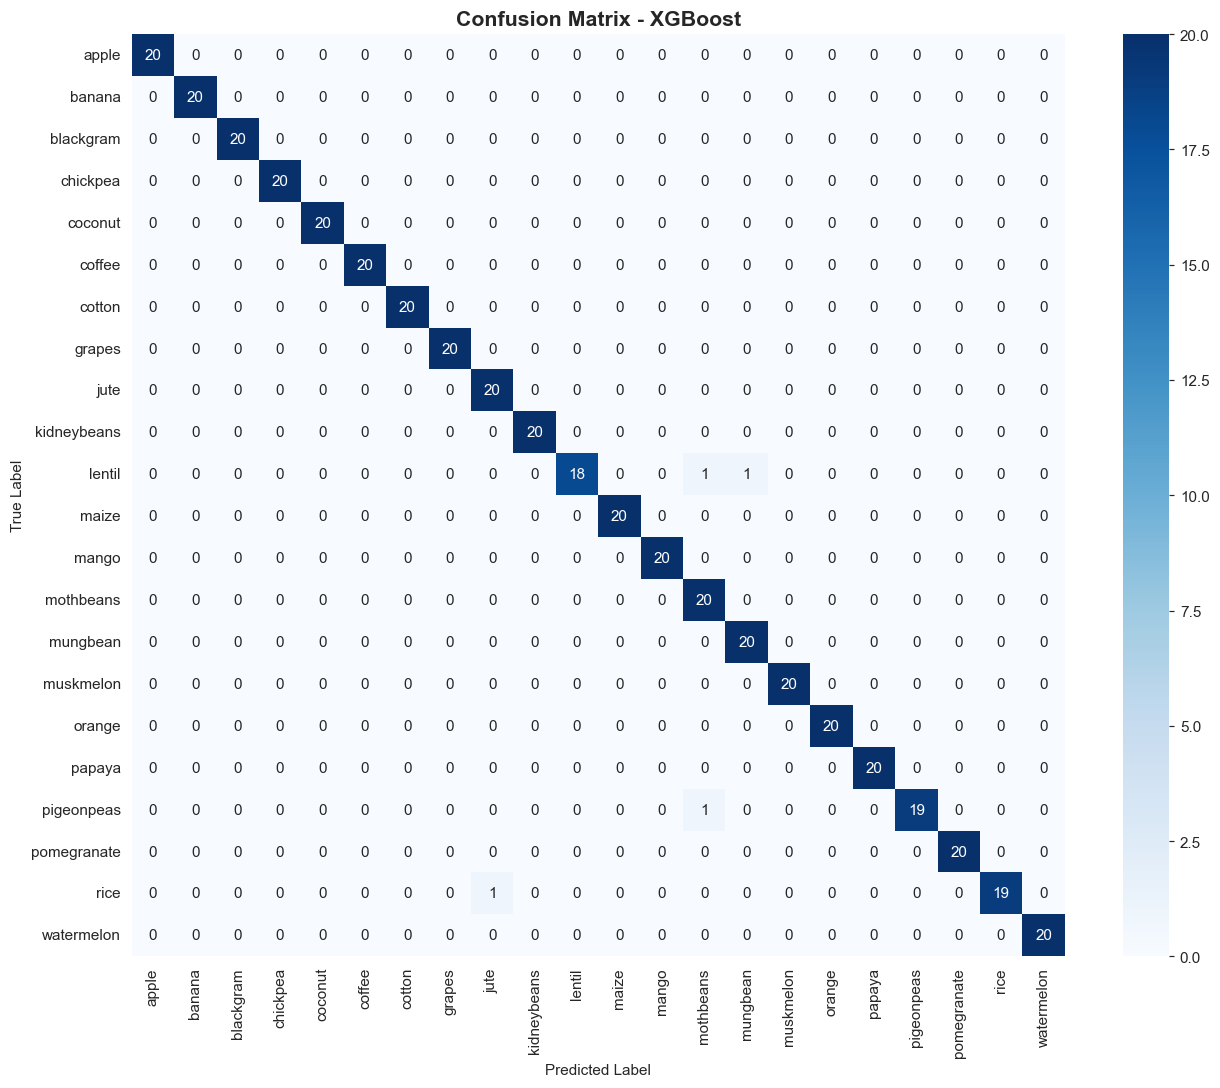

In [14]:
# 7a. Confusion Matrix
plt.figure(figsize=(12, 10))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title("Confusion Matrix - XGBoost", fontsize=14, fontweight="bold")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/07_confusion_matrix.png")
plt.show()
plt.close()

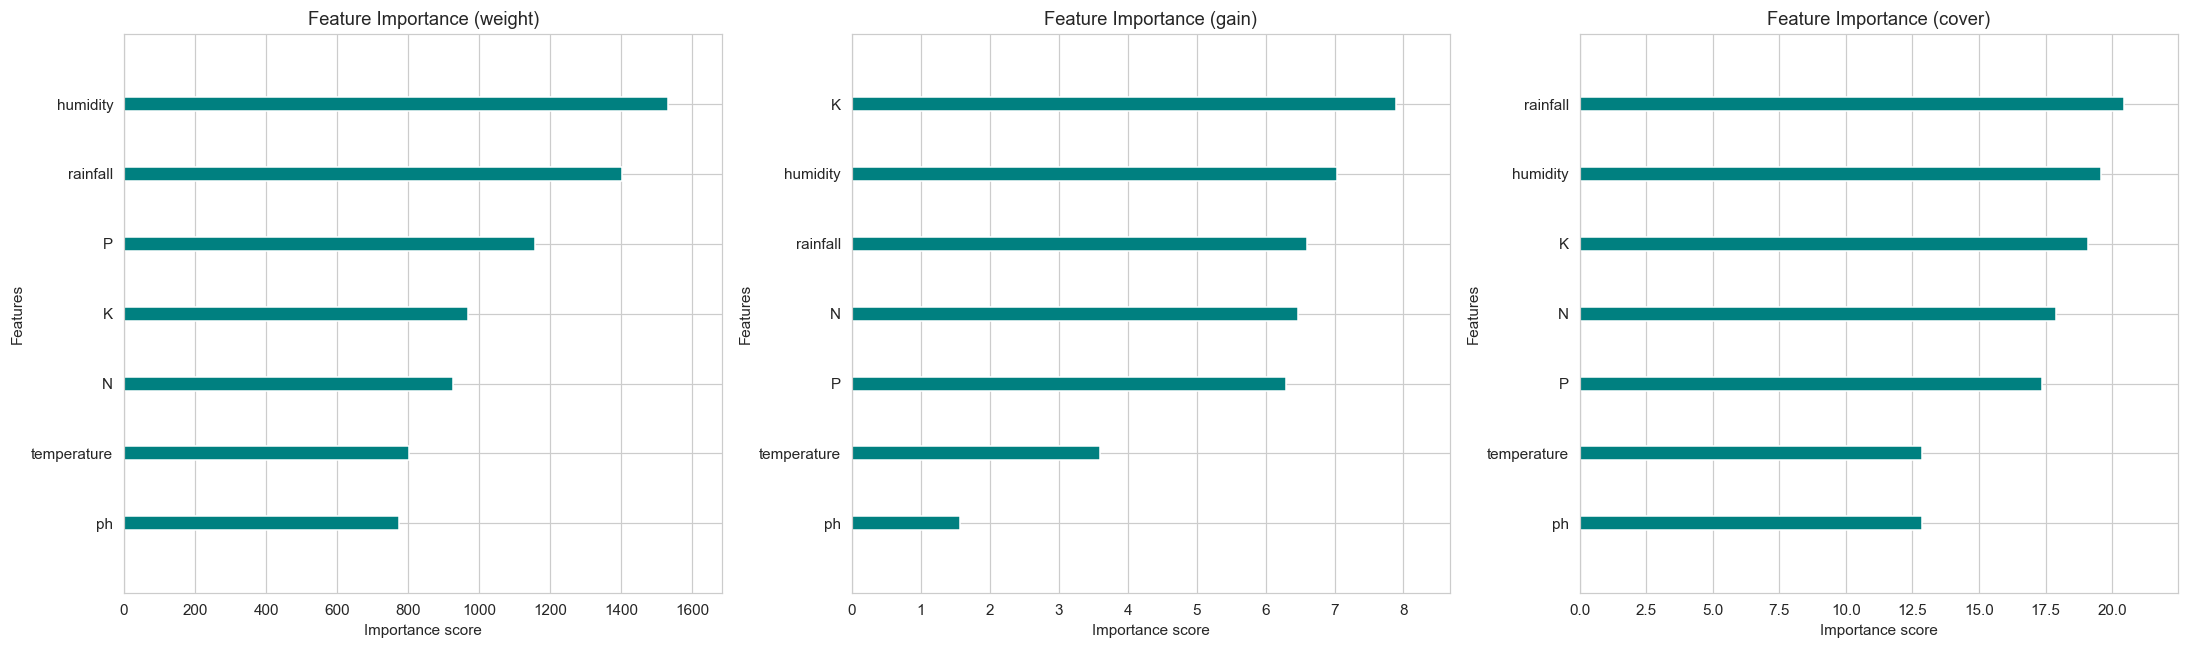

In [15]:
# 7b. Feature Importance (multiple types)
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
importance_types = ["weight", "gain", "cover"]
for ax, imp_type in zip(axes, importance_types):
    xgb.plot_importance(xgb_clf, importance_type=imp_type, ax=ax,
                         title=f"Feature Importance ({imp_type})",
                         color="teal", show_values=False)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/08_feature_importance.png")
plt.show()
plt.close()

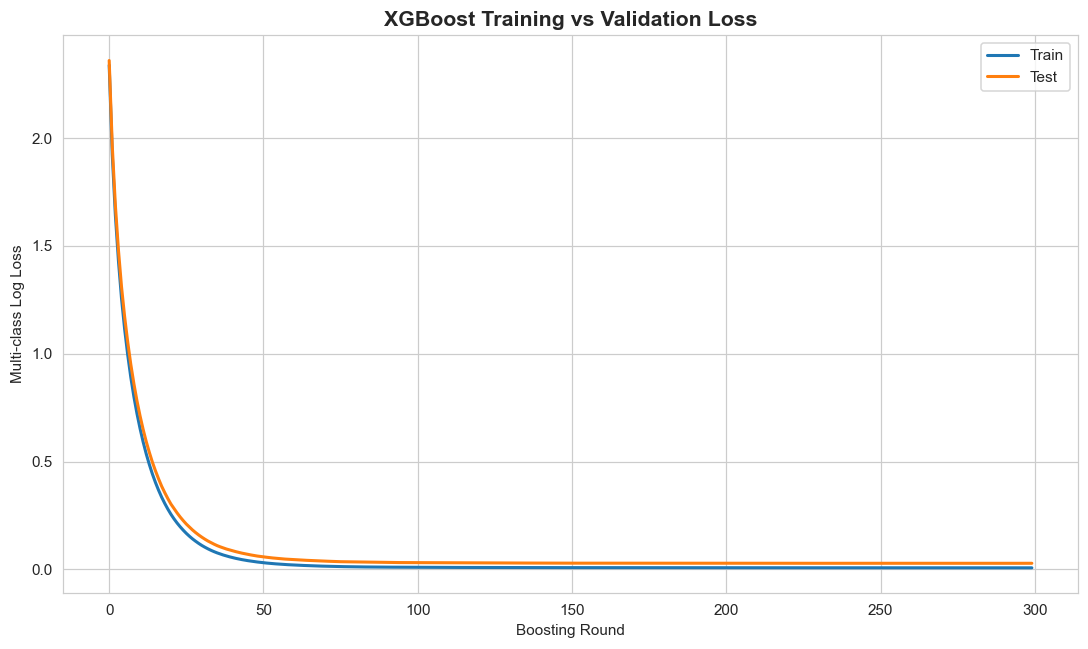

In [16]:
# 7c. Training vs Validation loss curve
results = xgb_clf.evals_result()
epochs = len(results["validation_0"]["mlogloss"])
x_axis = range(epochs)
plt.figure(figsize=(10, 6))
plt.plot(x_axis, results["validation_0"]["mlogloss"], label="Train", linewidth=2)
plt.plot(x_axis, results["validation_1"]["mlogloss"], label="Test", linewidth=2)
plt.xlabel("Boosting Round")
plt.ylabel("Multi-class Log Loss")
plt.title("XGBoost Training vs Validation Loss", fontsize=14, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/09_training_curve.png")
plt.show()
plt.close()

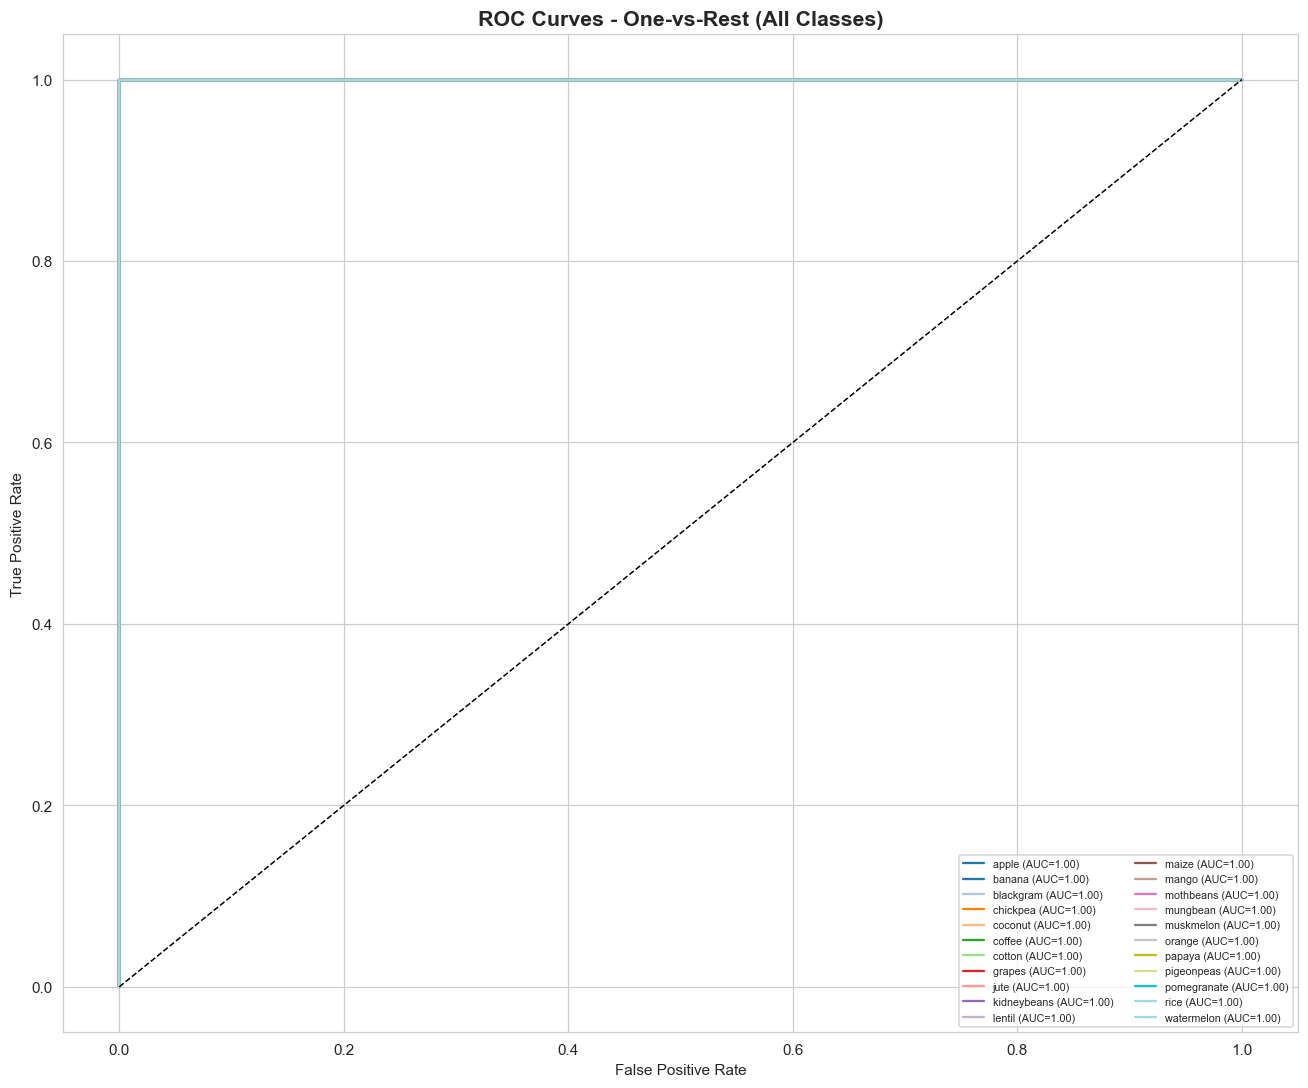

In [17]:
# 7d. ROC Curves (One-vs-Rest, multi-class)
y_test_bin = label_binarize(y_test, classes=range(len(le.classes_)))
n_classes = y_test_bin.shape[1]
 
fpr, tpr, roc_auc = {}, {}, {}
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])
 
plt.figure(figsize=(12, 10))
colors = plt.cm.tab20(np.linspace(0, 1, n_classes))
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=1.5,
              label=f"{le.classes_[i]} (AUC={roc_auc[i]:.2f})")
plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - One-vs-Rest (All Classes)", fontsize=14, fontweight="bold")
plt.legend(loc="lower right", fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/10_roc_curves.png")
plt.show()
plt.close()

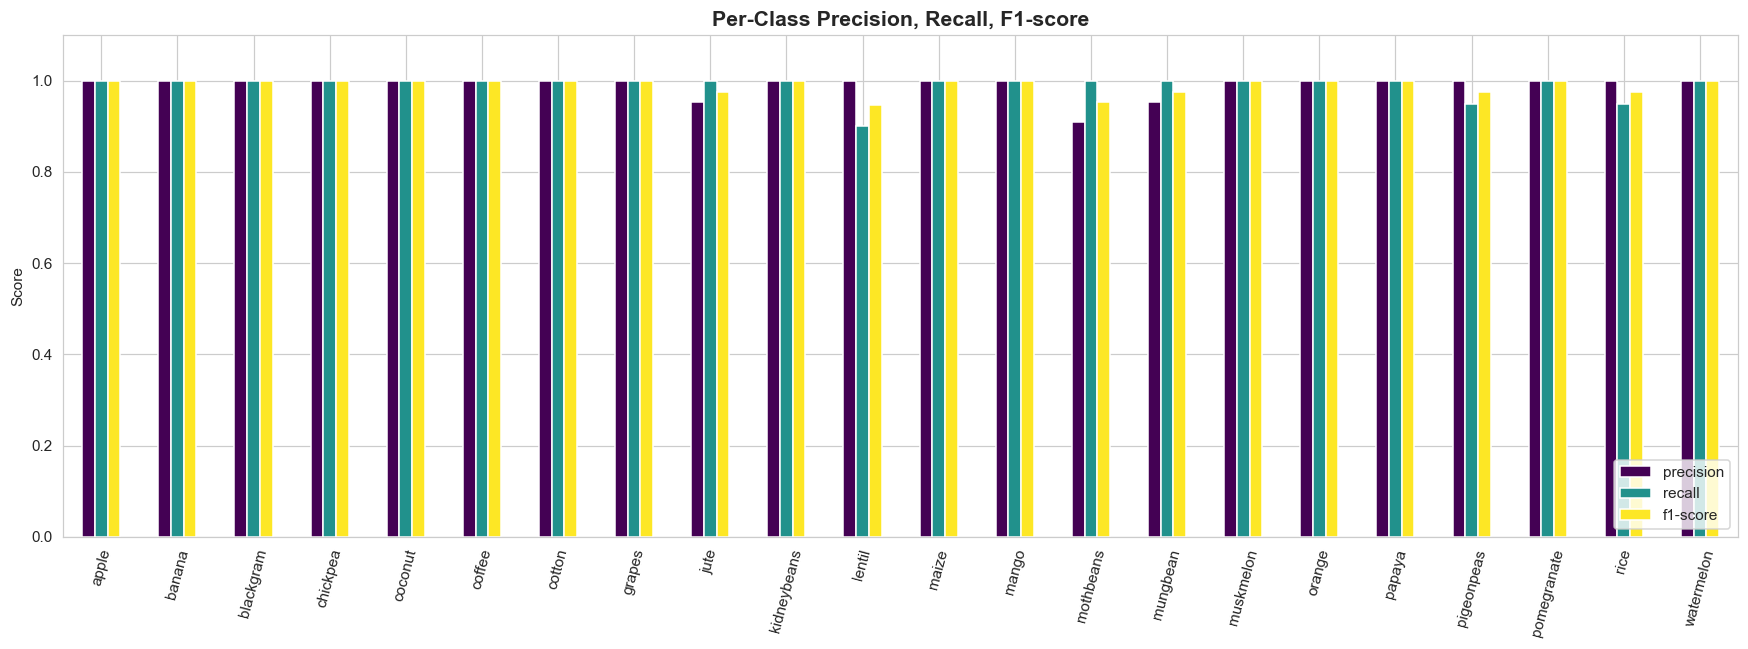

In [18]:
# 7e. Per-class Precision/Recall/F1 bar chart
report_dict = classification_report(y_test, y_pred, target_names=le.classes_, output_dict=True)
report_df = pd.DataFrame(report_dict).transpose().iloc[:-3]  # drop accuracy/avg rows
report_df[["precision", "recall", "f1-score"]].plot(
    kind="bar", figsize=(16, 6), colormap="viridis"
)
plt.title("Per-Class Precision, Recall, F1-score", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xticks(rotation=75)
plt.ylim(0, 1.1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/11_per_class_metrics.png")
plt.show()
plt.close()

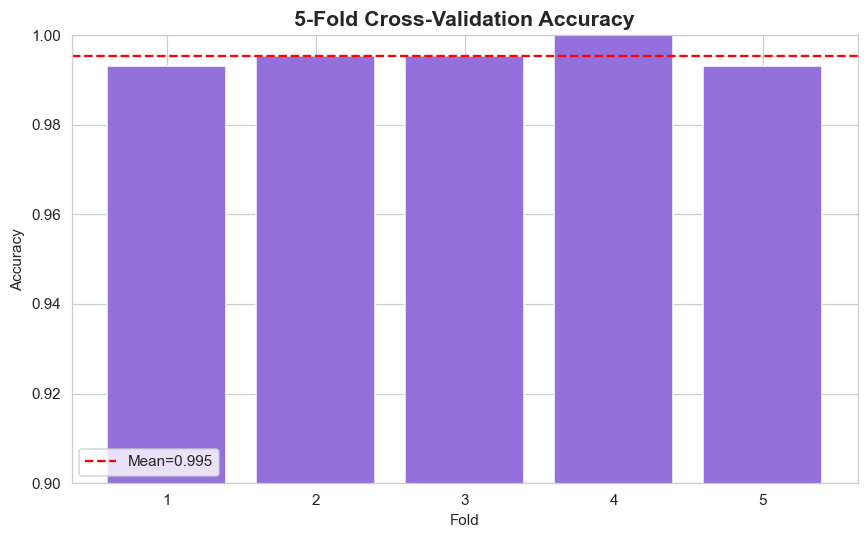


All evaluation visuals saved to: outputs


In [19]:
# 7f. CV score distribution
plt.figure(figsize=(8, 5))
plt.bar(range(1, len(cv_scores) + 1), cv_scores, color="mediumpurple")
plt.axhline(cv_scores.mean(), color="red", linestyle="--", label=f"Mean={cv_scores.mean():.3f}")
plt.xlabel("Fold")
plt.ylabel("Accuracy")
plt.title("5-Fold Cross-Validation Accuracy", fontsize=14, fontweight="bold")
plt.ylim(0.9, 1.0)
plt.legend()
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/12_cv_scores.png")
plt.show()
plt.close()
 
print("\nAll evaluation visuals saved to:", OUT_DIR)

#### SAVE MODEL + ARTIFACTS

In [20]:
import pickle
with open(f"{OUT_DIR}/xgboost_crop_model.pkl", "wb") as f:
    pickle.dump(xgb_clf, f)
with open(f"{OUT_DIR}/label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)
 
import os as _os
print("Model saved at:", _os.path.abspath(f"{OUT_DIR}/xgboost_crop_model.pkl"))
print("Label encoder saved at:", _os.path.abspath(f"{OUT_DIR}/label_encoder.pkl"))
print("\nModel and label encoder saved.")
print("\nDone! Summary:")
print(f"  Test Accuracy: {acc:.4f}")
print(f"  CV Accuracy:   {cv_scores.mean():.4f}")

Model saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\Crop_recommendation\outputs\xgboost_crop_model.pkl
Label encoder saved at: c:\Users\Aakash Kavediya\OneDrive\Documents\FarmerOS\Models\Crop_recommendation\outputs\label_encoder.pkl

Model and label encoder saved.

Done! Summary:
  Test Accuracy: 0.9909
  CV Accuracy:   0.9955
